In [ ]:
def metrics(y_true, y_pred):
    """Common regression skill scores for continuous targets (usually MAR).

    mae  — mean absolute error (same units as the target; lower is better)
    corr — Pearson correlation between observations and predictions
    r2   — coefficient of determination (1 = perfect; can be negative)
    """
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "corr": float(np.corrcoef(y_true.ravel(), y_pred.ravel())[0, 1]),
        "r2": float(r2_score(y_true, y_pred)),
    }


def plot_pred_scatter(y_train, train_pred, y_test, test_pred, title):
    """Observed vs predicted scatter for train and test sites.

    The dashed line is the 1:1 relation: predictions near it are accurate.
    """
    tr = metrics(y_train, train_pred)
    te = metrics(y_test, test_pred)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(y_train, train_pred, s=8, alpha=0.35, label=f"train MAE={tr['mae']:.2f}, r={tr['corr']:.3f}")
    ax.scatter(y_test, test_pred, s=8, alpha=0.45, label=f"test MAE={te['mae']:.2f}, r={te['corr']:.3f}")
    lims = [
        min(y_train.min(), y_test.min(), train_pred.min(), test_pred.min()),
        max(y_train.max(), y_test.max(), train_pred.max(), test_pred.max()),
    ]
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_xlabel("Observed")
    ax.set_ylabel("Predicted")
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.set_aspect("equal", adjustable="box")
    plt.tight_layout()
    plt.show()
    return tr, te


## Load MAR observations and environmental predictors

We assemble paired **features** (environmental predictors) and **labels**
(observed mass accumulation rate, MAR) from Coastal Sediment (CS) and Deep Ocean
(DO) core compilations.

Features are **neural-network imputed values only** (113 dimensions): originally
missing predictors were filled by a separate imputation model, then the continuous
values are used here. Sites are split **75% train / 25% test**, stratified by MAR
deciles so high- and low-MAR regimes appear in both sets.


In [1]:
# Load CS + DO MAR sites with a stratified train/test split.
# Returns feature matrices, labels, and the mean/std used later to standardize
# global ocean grids the same way as the training data.
mar = load_mar_cs_do(preprocess_features_labels)

train_features = mar["train_features"]  # predictors at training sites
train_labels = mar["train_labels"]      # observed MAR at training sites
test_features = mar["test_features"]    # held-out predictors
test_labels = mar["test_labels"]        # held-out MAR (for skill scores)
X_mean, X_std = mar["x_mean"], mar["x_std"]  # standardization from the train set
world_dir = mar["world_dir"]            # folder of global ocean feature chunks

print(f"n_features={mar['n_features']} (NN-imputed values only)")
print(f"train={train_features.shape}, test={test_features.shape}")
print(f"CS path: {mar['paths']['CS']}")
print(f"DO path: {mar['paths']['DO']}")
print(f"world: {world_dir}")


n_features=113 (NN-imputed values only)
train=(9860, 113), test=(3288, 113)
CS path: data/interim/inputfeatures/CS_men_masked
DO path: data/interim/inputfeatures/DO_men_masked
world: data/interim/worldfeatures/World_Features_men_masked


## Mini-batch iterators and loss function

The feed-forward network is trained with mini-batches of sites. **Huber loss**
is used as the objective so large MAR outliers do not dominate the fit.


In [ ]:
batch_size = 64  # sites per optimization step

# Pair each feature vector with its MAR label; shuffle training order each epoch
train_ds = TensorDataset(
    torch.tensor(train_features, dtype=torch.float64),
    torch.tensor(train_labels, dtype=torch.float64),
)
test_ds = TensorDataset(
    torch.tensor(test_features, dtype=torch.float64),
    torch.tensor(test_labels, dtype=torch.float64),
)
trainloader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
testloader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

# Robust regression loss (less sensitive to extreme MAR outliers than MSE alone)
loss_fn = torch.nn.HuberLoss()


## Fit the supervised feed-forward network

A fully connected network maps the 113 environmental predictors to MAR.
Hidden-layer widths `[128, 128, 128]` were selected by a held-out hyperparameter
search. Training uses Adam with weight decay and early stopping; the learning
curve (train vs test MAE) below diagnoses underfitting / overfitting.

Training uses Adam with learning rate $10^{-3}$ (as in the hyperparameter-search job for this architecture) and weight decay $10^{-4}$.


epoch: 0 | Training Loss: 76.814 | MAE: 77.302 | LR: 0.0010000 | count: 1/36 |
epoch: 0 | Testing Loss: 51.984 | MAE: 52.453 | count: 1/36 |
epoch: 1 | Training Loss: 55.286 | MAE: 55.759 | LR: 0.0010000 | count: 1/36 |
epoch: 1 | Testing Loss: 43.219 | MAE: 43.668 | count: 1/36 |
epoch: 2 | Training Loss: 50.223 | MAE: 50.688 | LR: 0.0010000 | count: 1/36 |
epoch: 2 | Testing Loss: 38.674 | MAE: 39.117 | count: 1/36 |
epoch: 3 | Training Loss: 45.948 | MAE: 46.406 | LR: 0.0010000 | count: 1/36 |
epoch: 3 | Testing Loss: 36.859 | MAE: 37.305 | count: 1/36 |
epoch: 4 | Training Loss: 43.750 | MAE: 44.207 | LR: 0.0010000 | count: 1/36 |
epoch: 4 | Testing Loss: 34.635 | MAE: 35.086 | count: 1/36 |
epoch: 5 | Training Loss: 41.302 | MAE: 41.756 | LR: 0.0010000 | count: 1/36 |
epoch: 5 | Testing Loss: 34.094 | MAE: 34.530 | count: 1/36 |
epoch: 6 | Training Loss: 40.024 | MAE: 40.476 | LR: 0.0010000 | count: 1/36 |
epoch: 6 | Testing Loss: 31.167 | MAE: 31.604 | count: 1/36 |
epoch: 7 | Tr

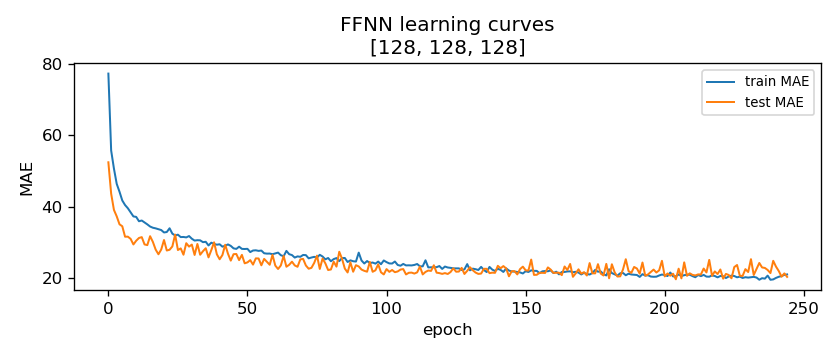

In [2]:
# Architecture from hyperparameter search (held-out MAR skill)
layer_widths = [128, 128, 128]
num_epochs = 1800  # upper bound; early stopping usually ends sooner

train_step = 2
write_maps = True  # if True, later cell writes a global MAR prediction map

features_all = mar["features"]
labels_all = mar["labels"]

set_seed(42)  # reproducible weight initialization
model = buildDNN(layer_widths, features_all)
model.apply(initialize_weights)
model.double()
if torch.cuda.is_available():
    model = model.cuda()
    loss_fn = loss_fn.cuda()

# Fit weights; returns per-epoch MAE curves used for the plot below
training_accuracy, training_losses, training_mae, learning_rate, evaluation_losses, evaluation_mae, true_labels, pred_labels = train_model(
    model, loss_fn, trainloader, testloader, num_epochs=num_epochs,
    lr=1e-3, weight_decay=1e-4,  # 1e-3 matches the hyperparameter-search run that produced these outputs
)

out_dir = PREDICTION_MAPS_DIR / "notebooks_nn"
out_dir.mkdir(parents=True, exist_ok=True)

# Learning curves: falling train+test MAE → improving fit
plt.figure(figsize=(7, 3))
plt.plot(training_mae, label="train MAE")
plt.plot(evaluation_mae, label="test MAE")
plt.xlabel("epoch")
plt.ylabel("MAE")
plt.legend()
plt.title(f"FFNN learning curves\n{layer_widths}")
plt.tight_layout()
plt.show()  # figure is shown below this cell


## Evaluate predictive skill and map the global ocean

Score train/test sites, draw an observed-vs-predicted scatter, save weights, and
optionally predict MAR on the global feature grid (chunk by chunk) with land masked.

> **Note on displayed outputs.** Cell outputs (training logs, learning curves, scatter plots, and maps) are taken from the archived hyperparameter-search run of **this same architecture**, not from a fresh execution of the cells above. Metrics therefore match the selected configuration; cosmetic plot styling may differ slightly from what `plot_pred_scatter` would draw if re-run locally.


layer widths
[128, 128, 128]
evaluation losses
[tensor(23.2190, device='cuda:0', dtype=torch.float64), tensor(21.9898, device='cuda:0', dtype=torch.float64), tensor(20.4021, device='cuda:0', dtype=torch.float64), tensor(21.3317, device='cuda:0', dtype=torch.float64), tensor(20.3436, device='cuda:0', dtype=torch.float64)]
training loses
[array(20.0616863), array(20.38053711), array(20.57398523), array(20.91559913), array(21.03250966)]
[SI scatter] Saved scatter_entire_nn.png: test MAE=20.18 CC=0.906
[SI scatter] Saved checkpoint /gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/models/FFNN_nomask_[128,128,128]_from_hp_sweep.pt
+++++++++test results+++++++++
(3288,)
(3288,)
correlation coefficient:
0.9057457930931277
mae:
20.181937993073152
mse:
7199.954484106475
rmse:
84.85254553698714
+++++++++all results+++++++++
correlation coefficient:
0.9386032777131781
mae:
16.312730821403395
mse:
5239.592821838558
rmse:
72.38503175269427
+++++++++train results+++++++++
(9860,)
(9860,)
correl

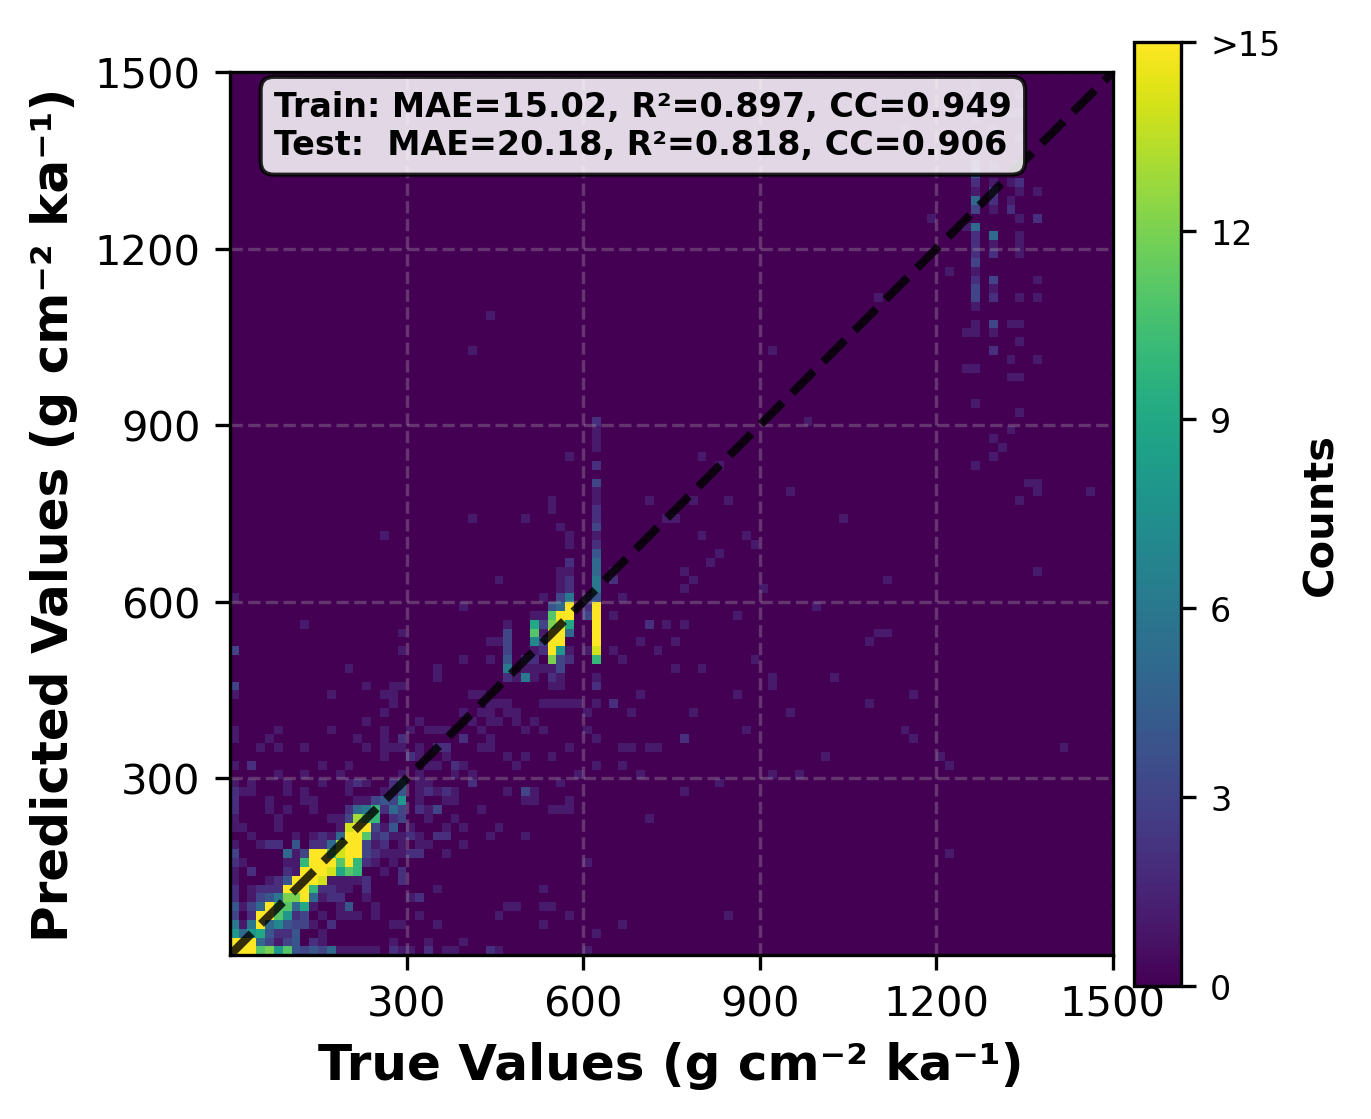

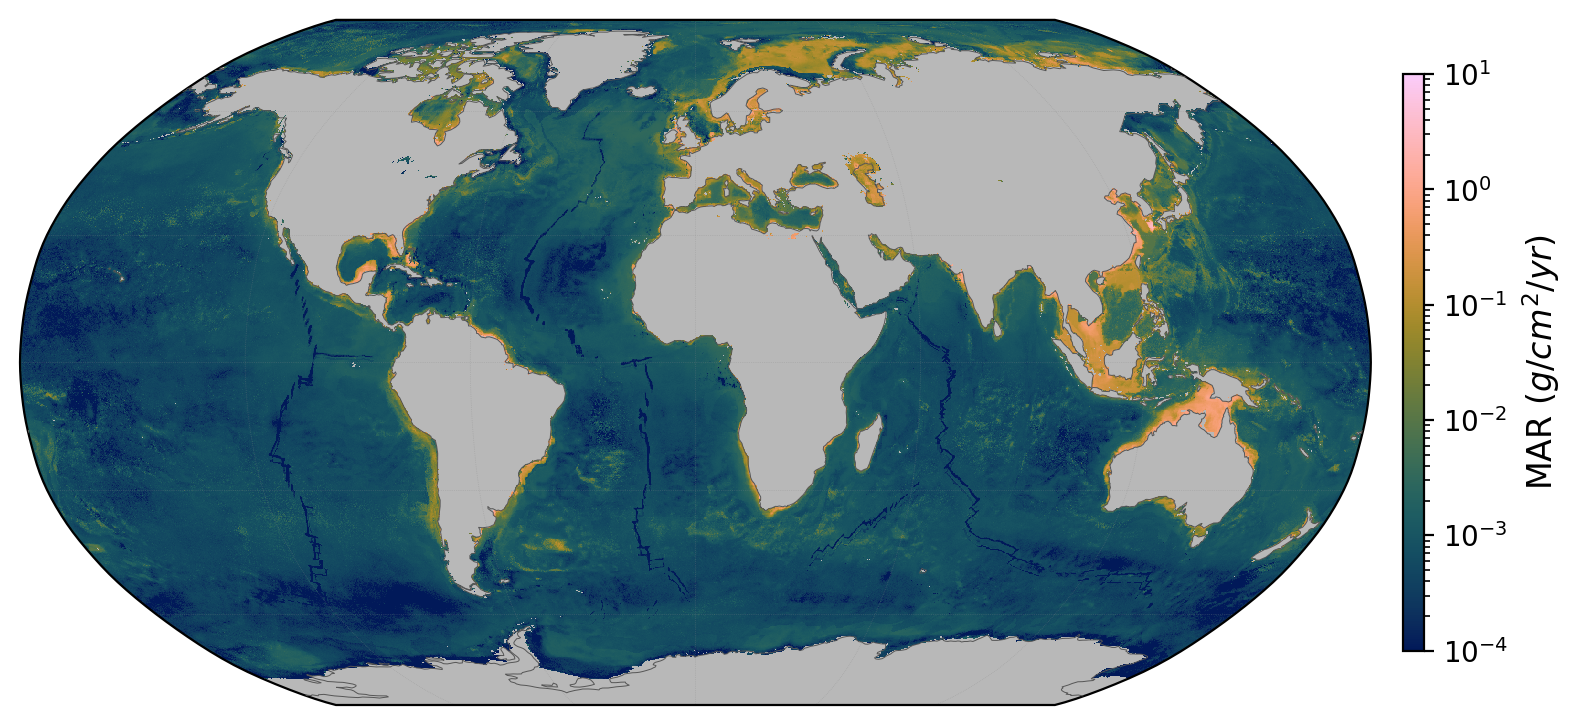

Saved weights: data/output/predictionmaps_SedRate/notebooks_nn/model_MAR_FFNN_[128,128,128]_nnimputed.pt


In [3]:
def collect_predictions(model, loader):
    """Run the network on every batch and collect labels + predictions."""
    model.eval()
    ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device=device, dtype=torch.float64)
            out = model(x)
            ys.append(y.numpy().reshape(-1))
            ps.append(out.detach().cpu().numpy().reshape(-1))
    return np.concatenate(ys), np.concatenate(ps)

y_tr, p_tr = collect_predictions(model, trainloader)
y_te, p_te = collect_predictions(model, testloader)
tr, te = plot_pred_scatter(y_tr, p_tr, y_te, p_te, f"FFNN {layer_widths}")
pd.DataFrame([{"model": "ffnn", "layer_widths": str(layer_widths), **{f"test_{k}": v for k, v in te.items()}}]).to_csv(
    out_dir / "nn_test_summary.csv", index=False
)

# Save weights for reuse / map reproduction
arch = str(layer_widths).replace(" ", "")
weight_path = out_dir / f"model_MAR_FFNN_{arch}_nnimputed.pt"
torch.save(model.state_dict(), weight_path)
print("Saved weights:", weight_path)

if write_maps:
    chunk_shape = (6, 4320)  # spatial layout of one stored world-feature file
    files = sorted(p for p in world_dir.iterdir() if p.suffix == ".npy")
    prediction_map = None
    model.eval()
    with torch.no_grad():
        for i, f in enumerate(files):
            feats = normalize_world_chunk(np.load(f), X_mean, X_std)
            t = torch.tensor(feats, dtype=torch.float64, device=device)
            preds = model(t).detach().cpu().numpy().reshape(chunk_shape)
            prediction_map = preds if prediction_map is None else np.append(prediction_map, preds, axis=0)
            if (i + 1) % 60 == 0:
                print(f"  predicted {i+1}/{len(files)} chunks")
            del t, feats
            gc.collect()
    land = np.load(DATA_RAW / "island_map.npy")
    land = np.where(np.isnan(land), 1, land).astype(bool)
    prediction_map = np.rot90(np.rot90(np.fliplr(prediction_map)))
    prediction_map[land] = 0
    map_path = out_dir / f"prediction_map_MAR_entire_FFNN_{arch}_nnimputed.npy"
    np.save(map_path, prediction_map)
    print("Saved map:", map_path)
